# Innovation Diffusion Analysis: Oura Ring 4
**DS 223 Marketing Analytics — Homework 1 (Bass Model)**

This notebook goes through all seven steps of the assignment. The Bass model formulas are exactly those from the lecture slides (*Bass Model for Innovation Diffusion*, K. Hovhannisyan). The R code from the slides is ported to Python in `helper_functions.py`.

## 1. The innovation: Oura Ring 4

**TIME Best Inventions 2025 entry:** [Oura Ring 4](https://time.com/collections/best-inventions-2025/7318554/oura-ring-4/)

The Oura Ring 4 is a titanium smart ring from the Finnish company that pioneered the category. According to TIME, it has more than twice as many signal pathways as its predecessor. Its "smart sensing" captures blood oxygen, heart and respiratory rate, skin-temperature changes and movement, and the subscription feature Symptom Radar flags early signs of respiratory illness. Oura sells the ring for about USD 349 plus a USD 5.99/month membership.

The unit of adoption here is **an Oura ring sold** (all generations, with Ring 4 as the current flagship). That matches how the look-alike data is measured (devices sold) and how Oura reports its milestones.

## 2. Look-alike innovation: Fitbit fitness trackers (2011–2019)

The closest historical analogue is the **Fitbit** wrist-worn fitness tracker. **Functionally**, both are screenless or minimal-screen wearables that sit on the body 24/7 and passively record activity, sleep and heart rate. Both turn those signals into scores (Fitbit's steps and Sleep Score; Oura's Readiness and Sleep scores) shown in a companion app. Neither tries to replace the phone the way a smartwatch does. Both are *health trackers first*. **Technologically**, both combine an accelerometer with optical PPG heart-rate sensing and later temperature/SpO₂ sensors, sync over Bluetooth Low Energy, and push analytics to the cloud. Both added paid subscriptions (Fitbit Premium in 2019, Oura Membership in 2021).

On **market impact**, Fitbit created and dominated the mass consumer fitness-tracker category, much as Oura created and dominates smart rings. Omdia puts Oura at about 74% of global smart-ring shipments ([Wareable](https://www.wareable.com/wearable-tech/oura-smart-ring-sales-five-million-market-report)), and IDC estimates more than 80% ([TechCrunch](https://techcrunch.com/2025/10/14/smart-ring-maker-oura-raises-900m-from-fidelity)). Both spread largely through word of mouth and social comparison (step challenges, sharing sleep scores, celebrity and athlete endorsement), which is the imitation mechanism *q* in the Bass model. Fitbit's full product lifecycle (launch, rapid growth, peak in 2016, decline) is also documented in audited SEC filings, so it can stand in for the curve that Oura is still on.

## 3. Historical data

Annual **Fitbit devices sold** (thousand units). 2012–2019 come from Fitbit Inc.'s audited Form 10-K filings ([FY2016](https://www.sec.gov/Archives/edgar/data/0001447599/000144759917000010/fitbit1231201610k.htm), [FY2019](https://www.sec.gov/Archives/edgar/data/1447599/000144759920000016/fit-20191231.htm)). 2011 comes from the company's S-1 IPO filing as reported by [MobiHealthNews](https://www.mobihealthnews.com/news/fitbit-files-ipo-sold-nearly-11-million-fitness-devices-2014). Series after 2019 is not used: Fitbit was acquired by Google (closed Jan 2021) and stopped reporting units. The source for every row is in `data/fitbit_devices_sold.csv`.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from helper_functions import fit_nls, fit_bass_ols, peak_time

fitbit = pd.read_csv("data/fitbit_devices_sold.csv")
fitbit[["year", "devices_sold_thousands"]]

,year,devices_sold_thousands
0,2011,200
1,2012,1279
2,2013,4476
3,2014,10904
4,2015,21355
5,2016,22295
6,2017,15343
7,2018,13939
8,2019,15988


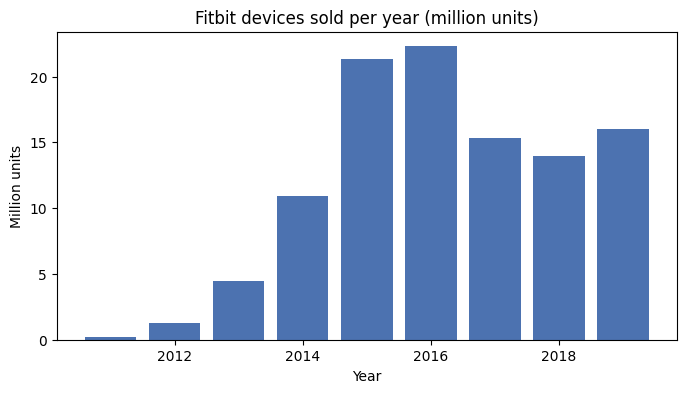

In [2]:
years = fitbit["year"].values
sales = fitbit["devices_sold_thousands"].values / 1000   # million units
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(years, sales, color="#4C72B0")
ax.set(title="Fitbit devices sold per year (million units)",
       xlabel="Year", ylabel="Million units")
plt.show()

## 4. Estimating the Bass model parameters

As in the slides, with $f(t)$ the fraction adopting at time $t$ and $F(t)$ the cumulative fraction:

$$\frac{f(t)}{1-F(t)} = p + q\,F(t), \qquad
F(t)=\frac{1-e^{-(p+q)t}}{1+\frac{q}{p}e^{-(p+q)t}}, \qquad
f(t)=\frac{(p+q)^2 e^{-(p+q)t}}{p\left[1+\frac{q}{p}e^{-(p+q)t}\right]^2}$$

The number of adopters in period $t$ is $a(t)=M\,f(t)$, and cumulative adopters are $A(t)=M\,F(t)$, with $t=1,\dots,n$.

**Method 1: non-linear least squares** (slide 34). Fit $\text{sales}_t = M f(t)$ directly, using the same starting values as the slides' R `nls()` call ($M=\sum \text{sales}$, $p=0.02$, $q=0.4$).

**Method 2: Bass's OLS** (slides 13–14). Regress $a(t)=\beta_0+\beta_1A(t-1)+\beta_2A(t-1)^2$ with $\beta_0=pM$, $\beta_1=q-p$, $\beta_2=-q/M$, then solve for $M$, $p$, $q$.

*Implementation check:* on the slides' smartphone data, `fit_nls` gives $M\approx17{,}457$, $p=0.00533$, $q=0.366$. That matches the slide's R output ($17{,}450$, $0.00533$, $0.366$), so the Python port reproduces the lecture model.

In [3]:
nls = fit_nls(sales)
ols = fit_bass_ols(sales)
pd.DataFrame({
    "Method 1: NLS": [nls["p"], nls["q"], nls["m"], nls["r2"]],
    "NLS std. error": [nls["se_p"], nls["se_q"], nls["se_m"], np.nan],
    "Method 2: Bass OLS": [ols["p"], ols["q"], ols["m"], ols["r2"]],
}, index=["p (innovation)", "q (imitation)",
          "M (million devices)", "R²"]).round(4)

,Method 1: NLS,NLS std. error,Method 2: Bass OLS
p (innovation),0.0087,0.0053,0.0380
q (imitation),0.6703,0.1338,0.7304
M (million devices),122.3562,17.0038,107.4242
R²,0.8207,NaN,0.7041


Predicted peak: t* = 6.40 -> year 2016.4
Actual peak year: 2016


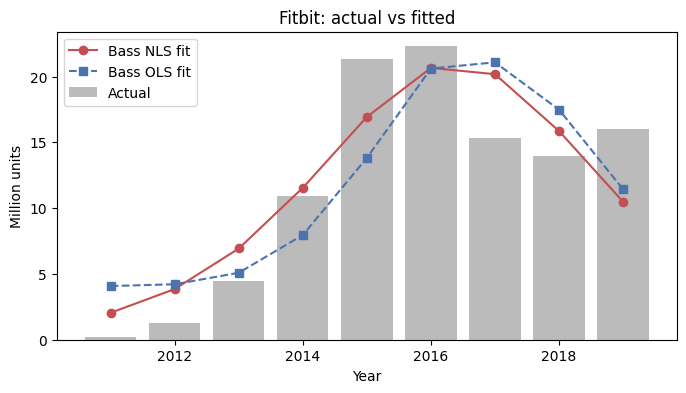

In [4]:
t_star = peak_time(nls["p"], nls["q"])
print(f"Predicted peak: t* = {t_star:.2f} -> year {years[0]-1+t_star:.1f}")
print(f"Actual peak year: {years[np.argmax(sales)]}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(years, sales, color="#BBBBBB", label="Actual")
ax.plot(years, nls["fitted"], "o-", color="#C44E52", label="Bass NLS fit")
ax.plot(years, ols["fitted"], "s--", color="#4C72B0", label="Bass OLS fit")
ax.set(title="Fitbit: actual vs fitted",
       xlabel="Year", ylabel="Million units")
ax.legend(); plt.show()

**Interpretation.** We carry forward the NLS estimates, the method the slides use for prediction: **p ≈ 0.009 and q ≈ 0.67**. The imitation effect is about 77 times the innovation effect, so Fitbit's growth came overwhelmingly from word of mouth. That fits a socially visible product promoted through friend challenges. Both values sit in the usual range for consumer durables; Sultan, Farley & Lehmann's (1990) meta-analysis reports mean values of p ≈ 0.03 and q ≈ 0.38. The model puts the peak at t* ≈ 6.4, i.e. **2016**, which is exactly the actual peak year.

The OLS method agrees on q (0.73) but gives a larger p. That is a known weakness of the discrete-time OLS estimator with only nine observations (Srinivasan & Mason, 1986). The fit is imperfect after 2017 (R² = 0.82) because Fitbit's sales levelled off at about 14–16M through replacement purchases and cheaper models instead of declining further. The basic Bass model only counts first purchases, so it can't capture that.

## 5–6. Scope and market potential for the Oura Ring

**Scope: global (in practice, high-income countries).** Oura sells online in dozens of countries and through retailers such as Amazon, Best Buy and Currys. It reports its sales milestones only worldwide (e.g. [Fortune, 2025](https://www.fortune.com/2025/09/23/oura-ring-11-billion-valuation-series-e-finland-875-million-raise-unicorn)), and no country-level unit data is public, so a single-country model could not be validated. The look-alike Fitbit series is also global. At about USD 349 plus a subscription, the ring is a premium product, so the addressable population is drawn from **high-income economies**.

**Market potential M (Fermi estimate).** All inputs are in `data/market_potential_inputs.json`.

| Factor | Value | Source |
|---|---|---|
| Population of high-income countries (2024) | 1,418 M | World Bank WDI via [FRED](https://fred.stlouisfed.org/series/SPPOPTOTLHIC) |
| × share aged 15+ | 84.3% | World Bank via [FRED](https://fred.stlouisfed.org/series/SPPOP0014TOZSHIC) |
| × wearable ownership rate | 41.1% | US HINTS 2024 ([PMC12795147](https://pmc.ncbi.nlm.nih.gov/articles/PMC12795147)), used as a proxy for high-income markets |
| × long-run smart-ring share of wearable owners | 2.5% / **5%** / 10% | Assumption: today rings are about 0.3% of wearable shipments (IDC: 1.7M of 537.9M, [2024](https://www.idc.com/resource-center/press-releases/idc-forecasts-continued-growth-for-wearables-but-growth-will-be-uneven-across-product-categories/)) and the category is growing about 88% per year |
| × Oura's share of smart rings | 74% | Omdia H1 2025 via [Wareable](https://www.wareable.com/wearable-tech/oura-smart-ring-sales-five-million-market-report) |
| **= M (million rings)** | **9.1 / 18.2 / 36.4** | low / base / high |

In [5]:
%run forecast_innovation.py

Adults in high-income countries: 1196 M
Wearable owners: 491 M
M (million rings): low 9.1, base 18.2, high 36.4
Calibrated diffusion origin t0 = 2020.50
   date  cumulative_rings_millions  predicted_millions
2020-04                       0.15                0.00
2021-05                       0.50                0.20
2022-03                       1.00                0.49
2024-06                       2.50                2.79
2025-09                       5.50                5.43
Peak adoption year: 2026.9
 year  new_base_m  cumulative_base_m
 2020        0.09               0.09
 2021        0.31               0.40
 2022        0.58               0.99
 2023        1.04               2.03
 2024        1.72               3.75
 2025        2.51               6.26
 2026        3.04               9.31
 2027        2.97              12.28
 2028        2.35              14.63
 2029        1.56              16.19
 2030        0.93              17.11
 2031        0.51              17.62
 2032    

## 5. Predicted diffusion path

The look-alike provides **p and q**, and the Fermi estimate provides **M**. Oura's ring had been on sale for years before Ring 4, so we fix the model's clock ($t=0$) by fitting it to Oura's *reported* cumulative sales (0.15M in 2020, 0.5M in 2021, 1M in March 2022, 2.5M in June 2024, 5.5M in September 2025; sources in `data/oura_milestones.csv`). This gives $t_0 \approx$ mid-2020, when Oura's sales began to scale. With no free parameters besides that time shift, the Fitbit-based curve predicts **2.8M by mid-2024 and 5.4M by September 2025**, against 2.5M and 5.5M actually reported. It also predicts about 2.5M rings sold in 2025, close to the "nearly 3 million" reported by [Fierce Healthcare](https://www.fiercehealthcare.com/health-tech/oura-raises-900m-series-e-oura-ring-sales-catapult).

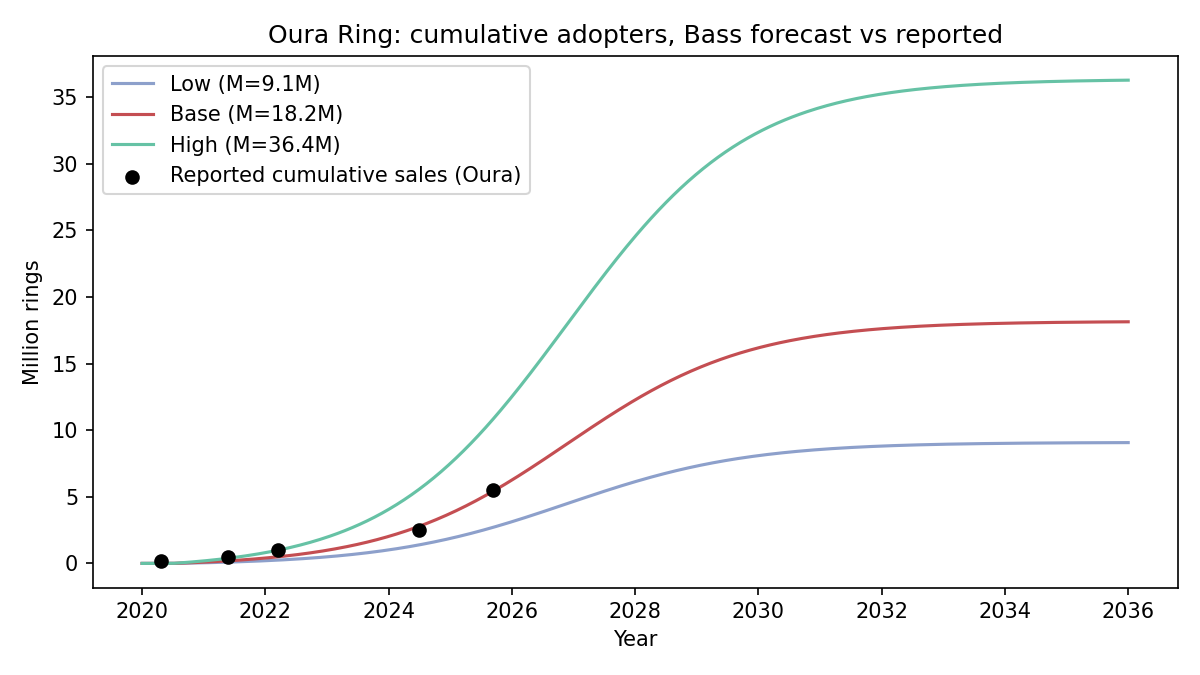

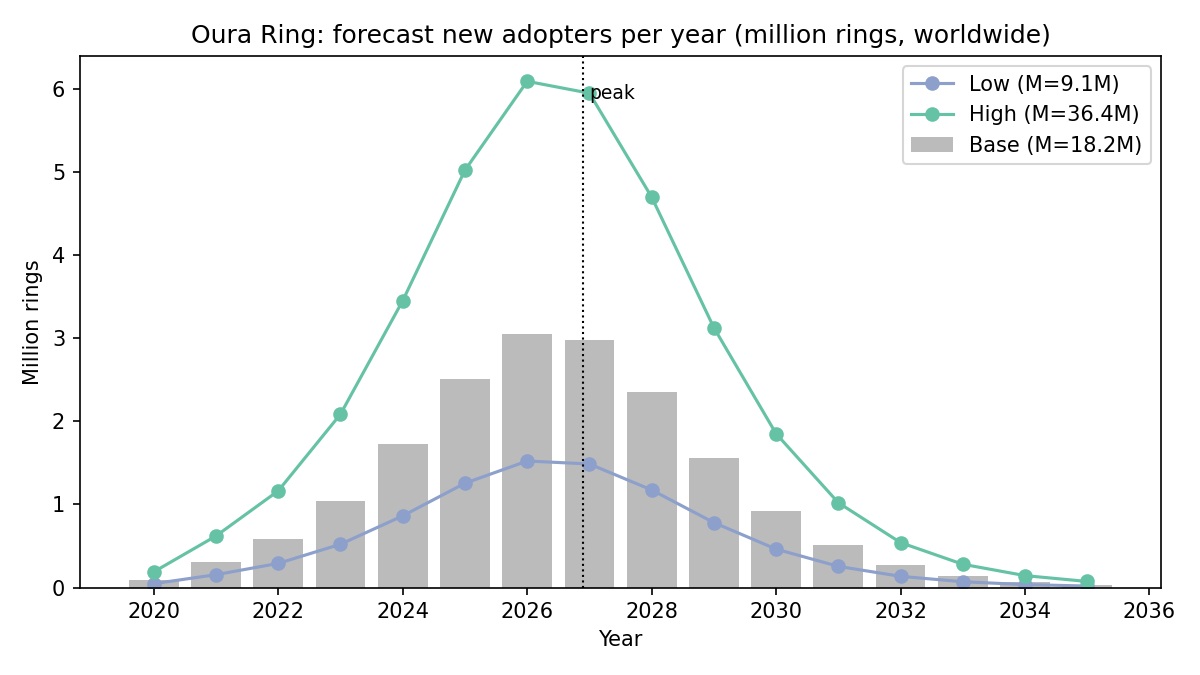

In [6]:
display(Image("img/oura_cumulative.png"))
display(Image("img/oura_forecast.png"))

## 7. Estimated adopters by period (million rings, worldwide)

New adopters in each calendar year are $A(\text{end of year}) - A(\text{start of year})$. The base scenario is $M = 18.2$M.

In [7]:
fc = pd.read_csv("data/oura_forecast.csv")
fc = fc[fc.year >= 2024].set_index("year").round(2)
new = fc[["new_low_m", "new_base_m", "new_high_m"]]
cum = fc[["cumulative_low_m", "cumulative_base_m", "cumulative_high_m"]]
print("New adopters per year (million rings)"); display(new)
print("Cumulative adopters, end of year (million rings)"); display(cum)

New adopters per year (million rings)


,new_low_m,new_base_m,new_high_m
year,,,
2024,0.86,1.72,3.45
2025,1.25,2.51,5.02
2026,1.52,3.04,6.09
2027,1.49,2.97,5.94
2028,1.17,2.35,4.70
2029,0.78,1.56,3.12
2030,0.46,0.92,1.85
2031,0.26,0.51,1.02
2032,0.14,0.27,0.54


Cumulative adopters, end of year (million rings)


,cumulative_low_m,cumulative_base_m,cumulative_high_m
year,,,
2024,1.88,3.75,7.51
2025,3.13,6.26,12.52
2026,4.65,9.31,18.61
2027,6.14,12.28,24.56
2028,7.31,14.63,29.25
2029,8.09,16.19,32.38
2030,8.56,17.11,34.23
2031,8.81,17.62,35.25
2032,8.95,17.89,35.79


**Conclusions.**
- Under Fitbit-like dynamics, Oura's ring is now in its **steepest growth phase**. Annual adoptions peak around **2026–2027** at about 3.0M rings per year (base case), and the predicted peak t* falls in late 2026.
- In the base case, cumulative adopters reach about 9M by the end of 2026 and about 17M by 2030. After that the market is about 95% saturated with first-time buyers, and sales come mainly from replacements and upgrades (as with Fitbit after 2017). The basic Bass model does not include those.
- The forecast is most sensitive to **M**. If smart rings win 10% of wearable owners rather than 5% (for example, if Samsung and Apple enlarge the category), M doubles to about 36M. Because the curve is anchored to observed sales, p and q matter less.
- Limitations: p and q are borrowed from a different (cheaper, wrist-worn) product. The ownership rate is a US figure extrapolated to all high-income countries. Repeat purchases are ignored, and competition from Samsung's Galaxy Ring and other entrants could cut Oura's 74% share.

## References
See `references.md` for the full list.